# Đặng Văn Chung - 24174800194

#Bài tập tuần 4

Chuẩn bị dữ liệu

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import confusion_matrix

SEED = 42
BATCH_SIZE = 64
VAL_SIZE = 10_000

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

X_train = X_train_full[:-VAL_SIZE].astype("float32") / 255.0
y_train = y_train_full[:-VAL_SIZE]
X_val = X_train_full[-VAL_SIZE:].astype("float32") / 255.0
y_val = y_train_full[-VAL_SIZE:]
X_test = X_test.astype("float32") / 255.0

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

Định nghĩa các hàm dùng chung

In [ ]:
from time import perf_counter
from IPython.display import Markdown, display

def train_mlp(hidden_units=(256, 128), learning_rate=1e-3, batch_size=64,
              dropout=0.0, l2_strength=0.0):
    tf.keras.utils.set_random_seed(SEED)

    train_data = (
        tf.data.Dataset.from_tensor_slices((X_train, y_train))
        .shuffle(len(X_train), seed=SEED)
        .batch(batch_size)
        .prefetch(tf.data.AUTOTUNE)
    )
    regularizer = tf.keras.regularizers.l2(l2_strength) if l2_strength else None
    layers = [tf.keras.layers.Input(shape=(28, 28)), tf.keras.layers.Flatten()]

    for layer_index, units in enumerate(hidden_units):
        layers.append(tf.keras.layers.Dense(
            units, activation="relu", kernel_regularizer=regularizer
        ))
        if dropout and layer_index < len(hidden_units) - 1:
            layers.append(tf.keras.layers.Dropout(dropout))

    layers.append(tf.keras.layers.Dense(len(class_names), activation="softmax"))
    network = tf.keras.Sequential(layers)
    network.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )

    started = perf_counter()
    fit_history = network.fit(
        train_data, validation_data=val_ds, epochs=40, shuffle=False, verbose=0,
        callbacks=[tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True
        )],
    )
    elapsed = perf_counter() - started

    curve = pd.DataFrame(fit_history.history)
    curve.index = np.arange(1, len(curve) + 1)
    best_epoch = int(curve["val_loss"].idxmin())
    best = curve.loc[best_epoch]
    _, test_acc = network.evaluate(test_ds, verbose=0)

    result = {
        "Tham số": network.count_params(),
        "Epoch đã chạy": len(curve),
        "Epoch tốt nhất": best_epoch,
        "Thời gian train (s)": elapsed,
        "Thời gian / epoch (s)": elapsed / len(curve),
        "Train accuracy (%)": best["accuracy"] * 100,
        "Validation accuracy (%)": best["val_accuracy"] * 100,
        "Test accuracy (%)": test_acc * 100,
        "Chênh lệch train/val (điểm %)": (best["accuracy"] - best["val_accuracy"]) * 100,
    }
    return network, curve, result


def show_results(runs, columns):
    table = pd.DataFrame({name: run[2] for name, run in runs.items()}).T[columns]
    count_columns = [c for c in columns if c in ("Tham số", "Epoch đã chạy", "Epoch tốt nhất")]
    display(table.astype({column: int for column in count_columns}).round(2))


def plot_curves(runs, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    for (name, (_, curve, result)), color in zip(runs.items(), colors):
        for ax, metric in zip(axes, ["loss", "accuracy"]):
            ax.plot(curve.index, curve[metric], "--", color=color, label=f"{name} · train")
            ax.plot(curve.index, curve[f"val_{metric}"], color=color, label=f"{name} · val")
            best = result["Epoch tốt nhất"]
            ax.scatter(best, curve.loc[best, f"val_{metric}"], color=color, s=22)
            ax.set(xlabel="Epoch", ylabel=metric.capitalize())
            ax.grid(alpha=0.25)

    axes[1].legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

### Bài 1. Thay đổi kiến trúc

- **Bước 1.** Huấn luyện ba MLP có tầng ẩn `(256,)`, `(256, 128)` và `(256, 128, 64)`. Giữ learning rate `0.001` và batch size `64`.
- **Bước 2.** Lập bảng số tham số, thời gian huấn luyện, validation accuracy và test accuracy. Dùng mô hình hai tầng làm đối chứng cho các bài sau.

In [ ]:
architecture_runs = {
    "1 tầng (256)": train_mlp(hidden_units=(256,)),
    "2 tầng (256, 128)": train_mlp(),
    "3 tầng (256, 128, 64)": train_mlp(hidden_units=(256, 128, 64)),
}
baseline = architecture_runs["2 tầng (256, 128)"]
accuracy_columns = ["Validation accuracy (%)", "Test accuracy (%)"]
show_results(architecture_runs, [
    "Tham số", "Epoch đã chạy", "Thời gian train (s)", *accuracy_columns,
])

,Tham số,Epoch đã chạy,Thời gian train (s),Validation accuracy (%),Test accuracy (%)
1 tầng (256),203530,8,12.80,88.33,87.53
"2 tầng (256, 128)",235146,12,19.75,89.06,88.65
"3 tầng (256, 128, 64)",242762,12,19.88,88.82,88.15


**Kết quả.** Hai tầng ẩn đạt validation accuracy cao nhất (89,06%). Thêm tầng thứ ba làm tăng số tham số và giảm test accuracy từ 88,65% xuống 88,15%.

### Bài 2. Thử learning rate

- **Bước 1.** Giữ hai tầng ẩn `(256, 128)` và batch size `64`. Thử learning rate `0.01`, `0.001` và `0.0001`, dùng lại đối chứng cho mức `0.001`.
- **Bước 2.** Vẽ đường loss và accuracy của train và validation. Với mỗi mức, lấy epoch có validation loss thấp nhất rồi đối chiếu mức dao động và accuracy.

,Epoch đã chạy,Epoch tốt nhất,Validation accuracy (%),Test accuracy (%)
1e-2,9,6,86.02,85.41
1e-3,12,9,89.06,88.65
1e-4,11,8,87.68,87.15


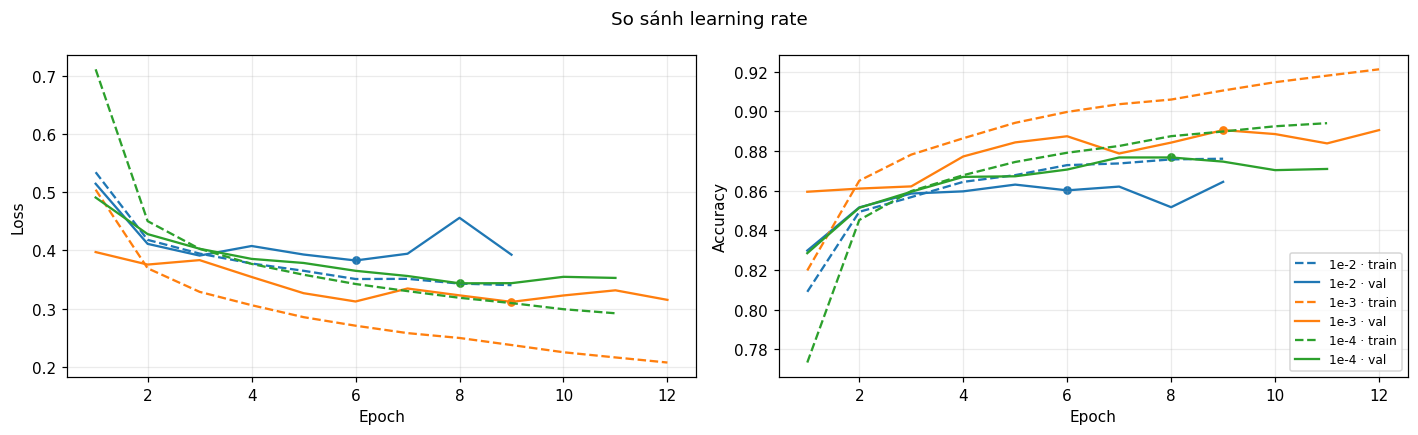

In [ ]:
lr_runs = {
    "1e-2": train_mlp(learning_rate=1e-2),
    "1e-3": baseline,
    "1e-4": train_mlp(learning_rate=1e-4),
}
show_results(lr_runs, ["Epoch đã chạy", "Epoch tốt nhất", *accuracy_columns])
plot_curves(lr_runs, "So sánh learning rate")

**Kết quả.** `1e-3` cho validation loss thấp nhất (0,3116). Với `1e-2`, validation loss dao động rõ hơn. Với `1e-4`, đường train accuracy thấp hơn `1e-3` trong các epoch đầu.

### Bài 3. Thử batch size

- **Bước 1.** Giữ kiến trúc `(256, 128)` và learning rate `0.001`. Lần lượt huấn luyện với batch size `32`, `128` và `512`.
- **Bước 2.** Lấy tổng thời gian huấn luyện chia cho số epoch đã chạy. So sánh thời gian mỗi epoch, tổng thời gian và accuracy giữa ba cấu hình.

In [ ]:
batch_runs = {str(size): train_mlp(batch_size=size) for size in (32, 128, 512)}
show_results(batch_runs, [
    "Epoch đã chạy", "Thời gian train (s)", "Thời gian / epoch (s)", *accuracy_columns,
])

,Epoch đã chạy,Thời gian train (s),Thời gian / epoch (s),Validation accuracy (%),Test accuracy (%)
32,9,23.10,2.57,88.48,88.22
128,10,10.58,1.06,88.82,87.96
512,17,12.00,0.71,89.25,88.70


**Kết quả.** Batch 512 nhanh nhất mỗi epoch và đạt validation accuracy cao nhất (89,25%). Batch 128 có tổng thời gian ngắn nhất với 10 epoch, so với 17 epoch của batch 512.

### Bài 4. Thêm Dropout

- **Bước 1.** Chèn `Dropout(0.3)` giữa `Dense(256)` và `Dense(128)`, giữ các thiết lập huấn luyện của đối chứng.
- **Bước 2.** Dùng trọng số ở epoch có validation loss thấp nhất của mỗi mô hình. Đánh giá train và validation ở chế độ suy luận, lấy train accuracy trừ validation accuracy rồi so sánh hai độ chênh.

,Epoch tốt nhất,Train accuracy (%),Validation accuracy (%),Test accuracy (%),Chênh lệch train/val (điểm %)
Đối chứng,9,91.06,89.06,88.65,2.00
Dropout 0.3,9,88.78,88.63,87.87,0.15


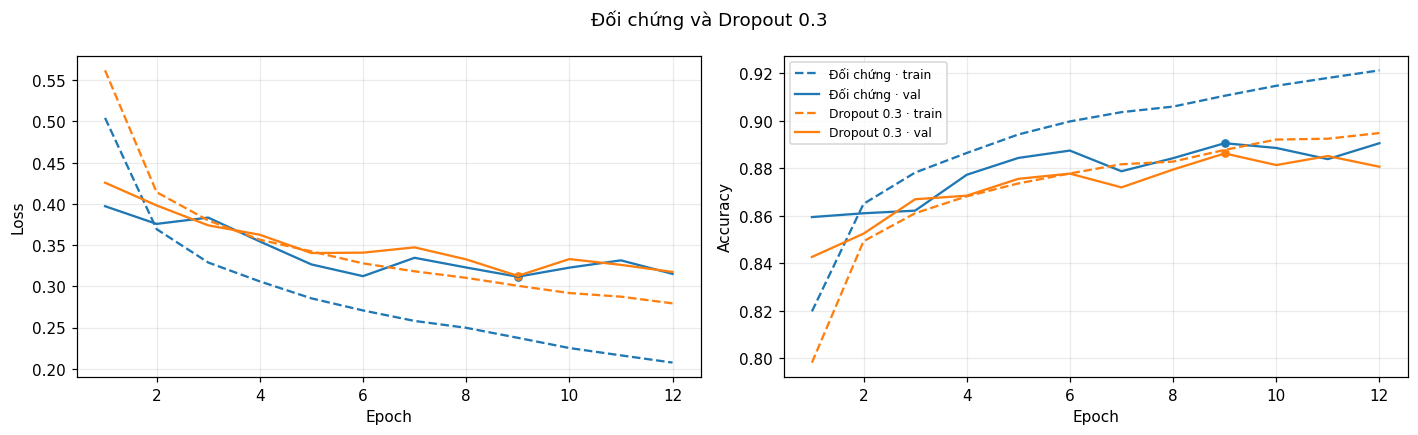

Khi đánh giá ở chế độ suy luận, chênh lệch train/validation của đối chứng là **3.22 điểm phần trăm**, của Dropout là **2.02 điểm phần trăm**.

In [ ]:
dropout_run = train_mlp(dropout=0.3)
dropout_runs = {"Đối chứng": baseline, "Dropout 0.3": dropout_run}
regularization_columns = [
    "Epoch tốt nhất", "Train accuracy (%)", *accuracy_columns,
    "Chênh lệch train/val (điểm %)",
]

train_eval_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train)).batch(BATCH_SIZE)

def inference_gap(run):
    network, _, result = run
    _, train_acc = network.evaluate(train_eval_ds, verbose=0)
    return train_acc * 100 - result["Validation accuracy (%)"]

gap_baseline = inference_gap(baseline)
gap_dropout = inference_gap(dropout_run)

show_results(dropout_runs, regularization_columns)
plot_curves(dropout_runs, "Đối chứng và Dropout 0.3")
display(Markdown(
    f"Khi đánh giá ở chế độ suy luận, chênh lệch train/validation của đối chứng "
    f"là **{gap_baseline:.2f} điểm phần trăm**, của Dropout là "
    f"**{gap_dropout:.2f} điểm phần trăm**."
))

**Kết quả.** Dropout thu hẹp chênh lệch train–validation, nhưng test accuracy giảm từ 88,65% xuống 87,87%.

### Bài 5. Thêm L2 regularization

- **Bước 1.** Thêm `kernel_regularizer=l2(1e-4)` vào cả hai tầng Dense ẩn và huấn luyện với các thiết lập của đối chứng.
- **Bước 2.** Tính lại chênh lệch train–validation ở chế độ suy luận như Bài 4. So sánh chênh lệch này và test accuracy với đối chứng.

,Epoch tốt nhất,Train accuracy (%),Validation accuracy (%),Test accuracy (%),Chênh lệch train/val (điểm %)
Đối chứng,9,91.06,89.06,88.65,2.00
L2 1e-4,9,90.10,88.78,88.03,1.32


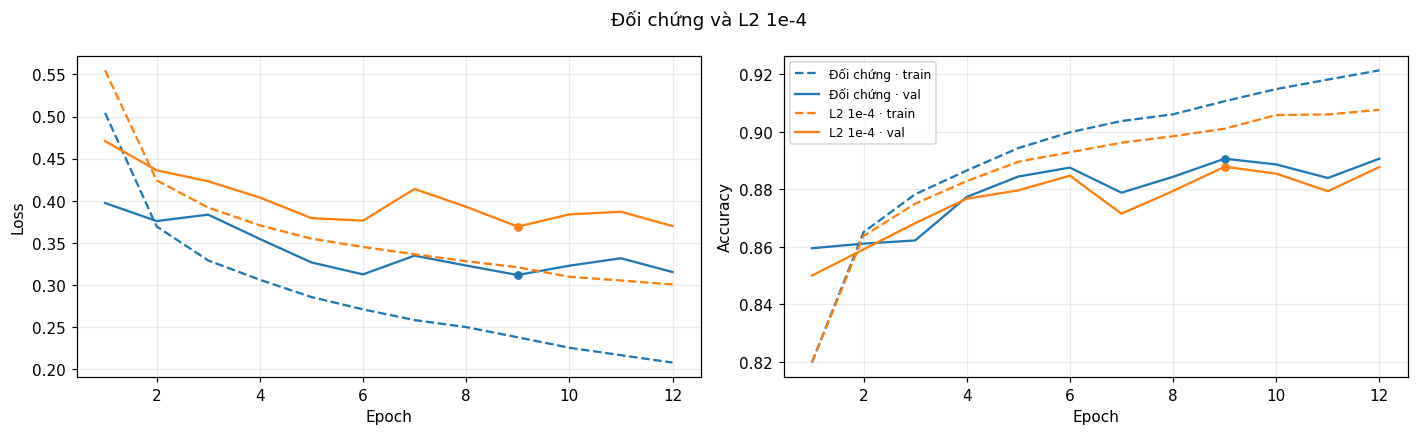

Với L2, chênh lệch train/validation khi suy luận là **2.40 điểm phần trăm**. Thay đổi so với đối chứng là **-0.28 điểm phần trăm** trên validation và **-0.62 điểm phần trăm** trên test.

In [ ]:
l2_run = train_mlp(l2_strength=1e-4)
l2_runs = {"Đối chứng": baseline, "L2 1e-4": l2_run}

show_results(l2_runs, regularization_columns)
plot_curves(l2_runs, "Đối chứng và L2 1e-4")

l2_gap = inference_gap(l2_run)
l2_val_delta = l2_run[2]["Validation accuracy (%)"] - baseline[2]["Validation accuracy (%)"]
l2_test_delta = l2_run[2]["Test accuracy (%)"] - baseline[2]["Test accuracy (%)"]
display(Markdown(
    f"Với L2, chênh lệch train/validation khi suy luận là **{l2_gap:.2f} điểm phần trăm**. "
    f"Thay đổi so với đối chứng là **{l2_val_delta:+.2f} điểm phần trăm** trên validation "
    f"và **{l2_test_delta:+.2f} điểm phần trăm** trên test."
))

**Kết quả.** L2 thu hẹp chênh lệch train–validation, đồng thời làm test accuracy giảm còn 88,03%.

### Bài 6. Phân tích lỗi

- **Bước 1.** Dùng mô hình đối chứng dự đoán tập test. Lấy lớp có xác suất cao nhất làm nhãn dự đoán và lọc các ảnh có nhãn dự đoán khác nhãn thật.
- **Bước 2.** Xếp các dự đoán sai theo xác suất của lớp được dự đoán, từ cao xuống thấp. Lấy 20 ảnh đầu và hiển thị chỉ số ảnh, nhãn thật, nhãn dự đoán và confidence.
- **Bước 3.** Chọn vài ảnh tiêu biểu và chỉ ra chi tiết hình dáng có thể gây nhầm giữa hai lớp.

,Chỉ số ảnh test,Nhãn thật,Dự đoán,Confidence (%)
Hạng,Unnamed: 1_level_1,Unnamed: 2_level_1,Unnamed: 3_level_1,Unnamed: 4_level_1
1,787,Trouser,Dress,99.96
2,5512,Ankle boot,Shirt,99.94
3,324,Coat,Shirt,99.93
4,9574,Pullover,Shirt,99.93
5,5235,Sandal,Bag,99.92
6,2856,Shirt,T-shirt/top,99.90
7,4394,Dress,Bag,99.88
8,2599,T-shirt/top,Bag,99.88
9,5155,Shirt,Pullover,99.86


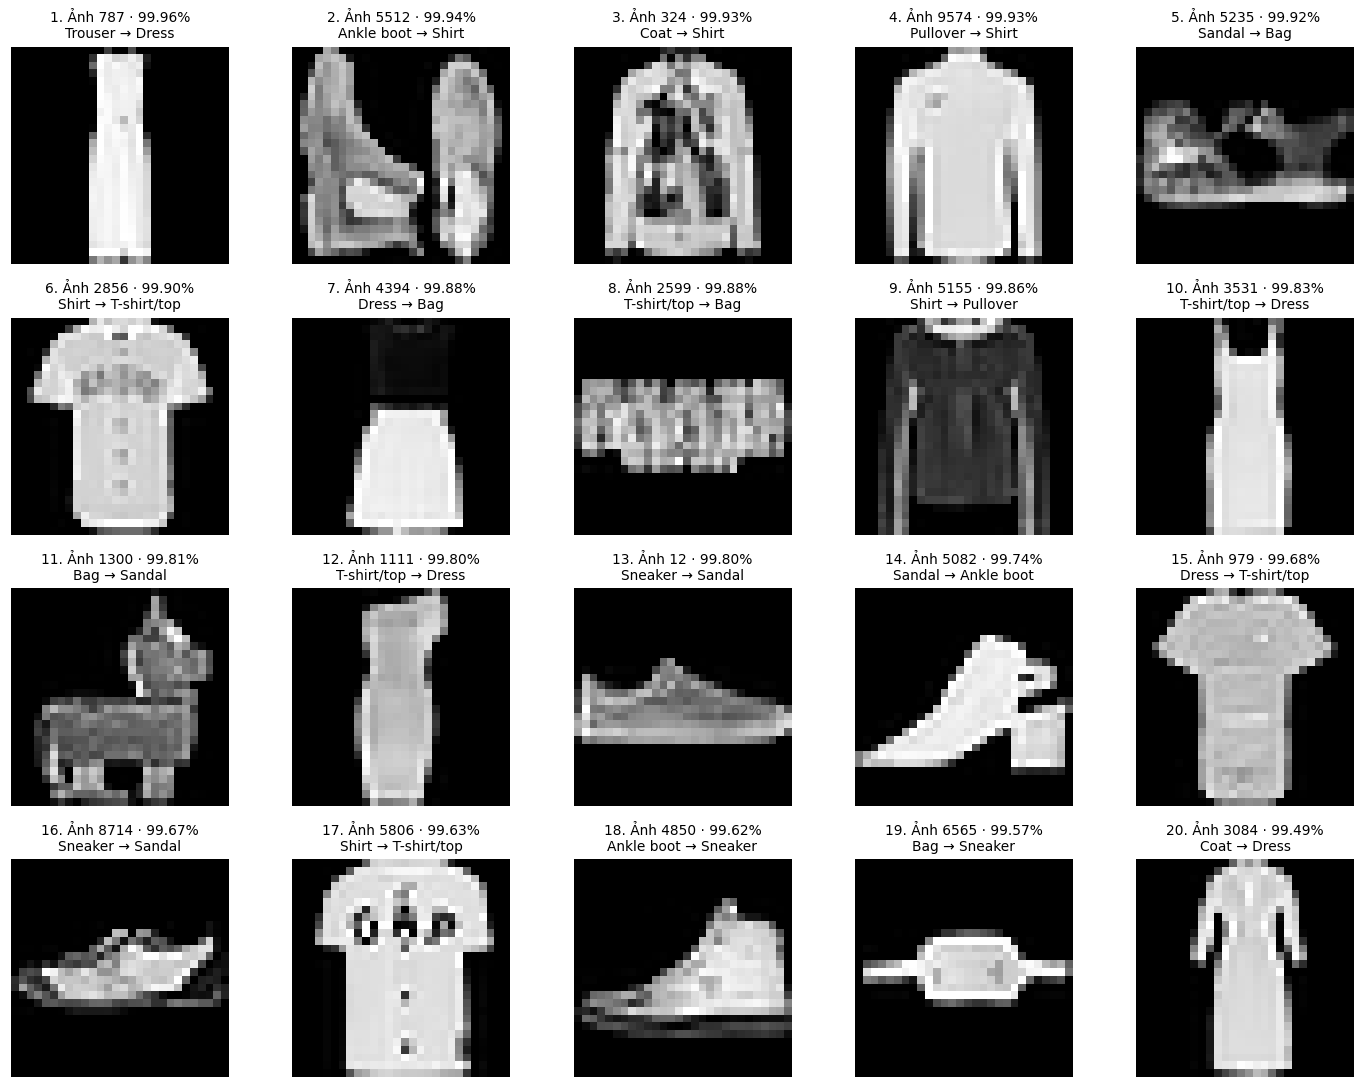

In [ ]:
baseline_net = baseline[0]
baseline_probs = baseline_net.predict(test_ds, verbose=0)
baseline_preds = baseline_probs.argmax(axis=1)
confidence = baseline_probs.max(axis=1)

wrong = np.flatnonzero(baseline_preds != y_test)
top_wrong = wrong[np.argsort(-confidence[wrong], kind="stable")[:20]]

error_table = pd.DataFrame({
    "Chỉ số ảnh test": top_wrong,
    "Nhãn thật": [class_names[label] for label in y_test[top_wrong]],
    "Dự đoán": [class_names[label] for label in baseline_preds[top_wrong]],
    "Confidence (%)": (100 * confidence[top_wrong].astype(float)).round(2),
}, index=pd.RangeIndex(1, len(top_wrong) + 1, name="Hạng"))

display(error_table)
fig, axes = plt.subplots(4, 5, figsize=(13, 10))
for ax in axes.flat:
    ax.axis("off")
for rank, (ax, index) in enumerate(zip(axes.flat, top_wrong), start=1):
    ax.imshow(X_test[index], cmap="gray")
    ax.set_title(
        f"{rank}. Ảnh {index} · {confidence[index]:.2%}\n"
        f"{class_names[y_test[index]]} → {class_names[baseline_preds[index]]}",
        fontsize=9,
    )
fig.tight_layout()
plt.show()

- **Ảnh 787 (Trouser → Dress)** có hai ống quần khó tách biệt, tạo dáng gần giống váy.
- **Ảnh 2856 và 5806 (Shirt → T-shirt/top)** có tay ngắn và đường viền giống áo phông.
- **Ảnh 12 và 8714 (Sneaker → Sandal)** nhìn rõ đế nhưng khó thấy đường viền thân giày.

## Báo cáo ngắn

Đối chứng dùng Flatten → Dense(256, ReLU) → Dense(128, ReLU) → Dense(10, Softmax). Cấu hình gồm Adam, Sparse Categorical Crossentropy, learning rate 0,001 và batch size 64.

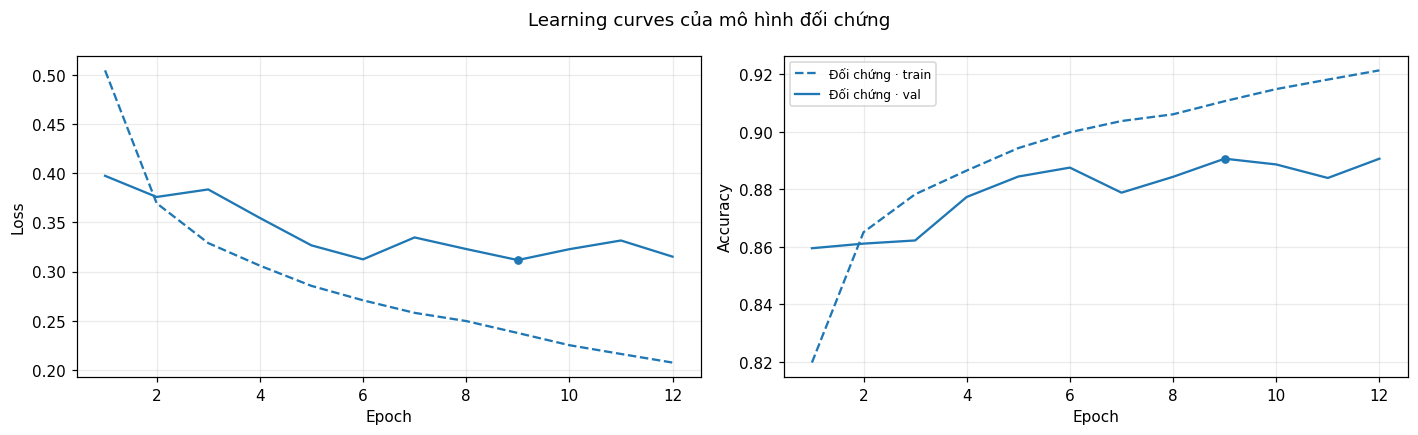

- **Đối chứng** đạt test accuracy **88,65%** ở epoch **9/12** (validation loss 0,3116).
- **Hai cặp nhầm nhiều nhất** là **T-shirt/top ↔ Shirt** (216 ảnh) và **Pullover ↔ Coat** (207 ảnh).
- **Đường học** cho thấy cả hai loss giảm lúc đầu, chưa có dấu hiệu underfitting rõ. Sau epoch 9, train loss giảm nhưng validation loss tăng nhẹ, cho thấy overfitting nhẹ.
- **Batch 512** đạt **89,25%** validation accuracy và **88,70%** test accuracy, tăng **0,05 điểm phần trăm** trên test.

In [ ]:
_, baseline_curve, baseline_result = baseline
best_epoch = baseline_result["Epoch tốt nhất"]
test_percent = baseline_result["Test accuracy (%)"]
last_epoch = len(baseline_curve)

cm_baseline = confusion_matrix(y_test, baseline_preds, labels=np.arange(len(class_names)))
pair_errors = sorted(
    ((int(cm_baseline[i, j] + cm_baseline[j, i]), i, j)
     for i in range(len(class_names)) for j in range(i + 1, len(class_names))),
    reverse=True,
)
pairs = ", ".join(
    f"**{class_names[i]} ↔ {class_names[j]}** ({total} ảnh)"
    for total, i, j in pair_errors[:2]
)
plot_curves({"Đối chứng": baseline}, "Learning curves của mô hình đối chứng")

alternatives = {
    **{name: run for name, run in architecture_runs.items() if run is not baseline},
    "Learning rate 1e-2": lr_runs["1e-2"],
    "Learning rate 1e-4": lr_runs["1e-4"],
    **{f"Batch size {size}": run for size, run in batch_runs.items()},
    "Dropout 0.3": dropout_run,
    "L2 1e-4": l2_run,
}
change = max(alternatives, key=lambda name: alternatives[name][2]["Validation accuracy (%)"])
change_result = alternatives[change][2]
change_test_delta = change_result["Test accuracy (%)"] - test_percent

display(Markdown(
    f"- **Đối chứng** đạt test accuracy **{test_percent:.2f}%** ở epoch "
    f"**{best_epoch}/{last_epoch}** (validation loss {baseline_curve.loc[best_epoch, 'val_loss']:.4f}).\n"
    f"- **Hai cặp nhầm nhiều nhất** là {pairs}.\n"
    f"- **Đường học** từ epoch {best_epoch} đến {last_epoch}. Train loss đổi từ "
    f"{baseline_curve.loc[best_epoch, 'loss']:.4f} thành {baseline_curve.iloc[-1]['loss']:.4f}, "
    f"validation loss đổi từ {baseline_curve.loc[best_epoch, 'val_loss']:.4f} thành "
    f"{baseline_curve.iloc[-1]['val_loss']:.4f}.\n"
    f"- **Thử nghiệm tốt nhất theo validation** là **{change}** với "
    f"**{change_result['Validation accuracy (%)']:.2f}%** validation accuracy và "
    f"**{change_result['Test accuracy (%)']:.2f}%** test accuracy "
    f"({change_test_delta:+.2f} điểm phần trăm trên test)."
))